# Testing the tests

The second notebook ended with its own list of shortcuts: it used monthly station data although the original study
used daily maximum and minimum temperatures; it trusted NOAA's corrections instead of making our own; its simple
climate model had fixed timescales; it used one run per climate model; and everything used the study's 42-year
windows. This notebook removes each shortcut in turn:

1. **Daily data.** Read the daily archive itself and build monthly and annual means from it.
2. **Our own homogenisation.** Write a break-detection method from scratch, test it on made-up data, then apply it
   to the real stations and compare with NOAA's and with an independent group's (Berkeley Earth).
3. **Model timescales.** Run the energy-balance model 135 times with different settings.
4. **Many runs per model.** Separate chance from model differences.
5. **Window choice.** Compute the trend for every possible start year and window length.

It reuses the `data` folder of the second notebook (run that one first, or let this one download what it needs).
The full analysis behind the essay used all 1,155 of the study's stations (2.5 GB of daily files); here we use 40
of them so the notebook runs in minutes.

In [1]:
import io
import tarfile
import time
import urllib.request
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.width", 110)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
DATA = Path("data")
(DATA / "daily").mkdir(parents=True, exist_ok=True)
WINDOWS = [(1857, 1898), (1899, 1940), (1941, 1982), (1983, 2024)]
rng = np.random.default_rng(7)
t_start = time.time()


def get(name, url):
    target = DATA / name
    if not target.exists():
        req = urllib.request.Request(url, headers={"User-Agent": "climate-data-notebook/1.0"})
        target.write_bytes(urllib.request.urlopen(req, timeout=600).read())
    return target


def trend(years, values):
    years, values = np.asarray(years, float), np.asarray(values, float)
    ok = ~np.isnan(values)
    x, y = years[ok] - years[ok].mean(), values[ok]
    return 10 * (x * y).sum() / (x * x).sum()


def window_trends(s):
    return {f"{a}-{b}": trend(s.loc[a:b].index, s.loc[a:b].values) for a, b in WINDOWS}


print("ready")

ready


`trend` here returns only the slope in °C per decade; the second notebook shows how to attach an uncertainty.

# Daily data

## What a daily record looks like

GHCN-Daily keeps one text file per station, `<station id>.dly`. Each line holds one month of one **element**:
`TMAX` (the day's highest temperature), `TMIN` (lowest), `PRCP` (precipitation) and many others. After the
21-character header come 31 blocks of 8 characters, one per day: a 5-character value in **tenths of a degree**
(so `253` is 25.3 °C), then three flags. The second flag is again the quality-control flag; `-9999` means missing.

We pick 40 of the study's stations, 20 in the US and 20 elsewhere, at random but reproducibly (the random generator
has a fixed **seed**, 7, so everyone gets the same 40).

In [2]:
inv = pd.read_fwf(get("ghcnd-inventory.txt", "https://www.ncei.noaa.gov/pub/data/ghcn/daily/ghcnd-inventory.txt"),
                  widths=[11, 9, 10, 5, 5, 5], names=["id", "lat", "lon", "element", "first", "last"])
tt = inv[inv.element.isin(["TMAX", "TMIN"])]
per = tt.groupby("id").agg(n=("element", "nunique"), first=("first", "max"), last=("last", "min"), lat=("lat", "first"), lon=("lon", "first"))
sample = per[(per.n == 2) & (per["first"] <= 1900) & (per["last"] >= 2020)]
us_ids = sample.index[sample.index.str.startswith("US")]
other = sample.index[~sample.index.str.startswith("US")]
pick = sorted(rng.choice(us_ids, 20, replace=False).tolist() + rng.choice(other, 20, replace=False).tolist())
for sid in pick:
    get(f"daily/{sid}.dly", f"https://www.ncei.noaa.gov/pub/data/ghcn/daily/all/{sid}.dly")
print(len(sample), "stations in the study's selection; downloaded", len(pick))
print(open(DATA / f"daily/{pick[0]}.dly").readline()[:70])

1155 stations in the study's selection; downloaded 40
ASN00023000183901PRCP    0  a    0  a    0  a   20  a    0  a    0  a 


## From days to months to years

The rules matter, so they are written out:

- a day counts only if it has both `TMAX` and `TMIN`, neither is flagged, and the maximum is not below the minimum;
- the day's mean temperature is **(TMAX + TMIN) / 2**, the convention in most national records;
- a month counts if it has at least 25 such days (a month with only ten days of data could miss a cold spell);
- a year counts if all 12 months count.

In [3]:
def daily_to_annual(sid):
    rec = {}
    for line in open(DATA / f"daily/{sid}.dly"):
        el = line[17:21]
        if el not in ("TMAX", "TMIN"):
            continue
        v = np.array([int(line[21 + 8 * d: 26 + 8 * d]) for d in range(31)], float)
        flagged = np.array([line[27 + 8 * d] != " " for d in range(31)])
        v[(v == -9999) | flagged] = np.nan
        rec[(int(line[11:15]), int(line[15:17]), el)] = v / 10
    months = []
    for (y, m, el), tmax in rec.items():
        if el == "TMAX" and (y, m, "TMIN") in rec:
            tmin = rec[(y, m, "TMIN")]
            ok = ~np.isnan(tmax) & ~np.isnan(tmin) & (tmax >= tmin)
            if ok.sum() >= 25:
                months.append((y, m, tmax[ok].mean(), tmin[ok].mean()))
    mo = pd.DataFrame(months, columns=["year", "month", "tmax", "tmin"])
    yr = mo.groupby("year").agg(n=("month", "size"), tmax=("tmax", "mean"), tmin=("tmin", "mean"))
    yr = yr[yr.n == 12].drop(columns="n")
    yr["t"] = (yr.tmax + yr.tmin) / 2
    return yr.assign(id=sid).reset_index()


daily = pd.concat([daily_to_annual(s) for s in pick])
print(daily.groupby("id").year.agg(["min", "max", "size"]).head())

              min   max  size
id                           
ASN00023000  1888  2025    98
ASN00026026  1886  2024   117
AU000011801  1877  2025   136
BKM00014652  1898  2005    60
CAN01018610  1899  2003    99


## Daily against monthly, station by station

The monthly archive of notebook 2 is built from the same observations. For each station and the years both have,
compare the 1983-2024 trend from our daily calculation with the one from the monthly file.

             daily  monthly
id                         
ASN00026026  0.010    0.010
AU000011801  0.532    0.223
HRE00105203  0.553    0.552
RSM00025551  0.542    0.538
RSM00034110  0.574    0.564
SIM00014015  0.662    0.662
SW000010537  0.582    0.584
SWE00139148  0.533    0.535

median 1983-2024 trend (°C/decade): {'daily': 0.357, 'monthly': 0.321}


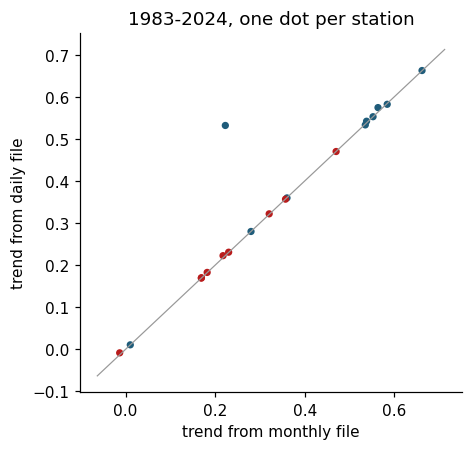

In [4]:
def open_member(kind, ending):
    tar = tarfile.open(get(f"ghcnm_{kind}.tar.gz", f"https://www.ncei.noaa.gov/pub/data/ghcn/v4/ghcnm.tavg.latest.{kind}.tar.gz"))
    member = next(m for m in tar.getmembers() if m.name.endswith(ending))
    return io.TextIOWrapper(tar.extractfile(member), encoding="ascii")


def monthly_annual(kind):
    cache = DATA / f"ghcnm_{kind}_annual.csv"
    if not cache.exists():
        rows = []
        for line in open_member(kind, ".dat"):
            v = [int(line[19 + 8 * m: 24 + 8 * m]) for m in range(12)]
            if -9999 in v or any(line[25 + 8 * m] != " " for m in range(12)):
                continue
            rows.append((line[:11], int(line[11:15]), sum(v) / 1200))
        pd.DataFrame(rows, columns=["id", "year", "t"]).to_csv(cache, index=False)
    return pd.read_csv(cache)


raw, noaa = monthly_annual("qcu"), monthly_annual("qcf")
both = daily.merge(raw, on=["id", "year"], suffixes=("_daily", "_monthly"))
both = both[both.year.between(1983, 2024)]
cmp_ = both.groupby("id").filter(lambda g: len(g) >= 30).groupby("id").apply(
    lambda g: pd.Series({"daily": trend(g.year, g.t_daily), "monthly": trend(g.year, g.t_monthly)}), include_groups=False)
print(cmp_.round(3).head(8))
print("\nmedian 1983-2024 trend (°C/decade):", cmp_.median().round(3).to_dict())

fig, ax = plt.subplots(figsize=(4.4, 4.2))
ax.scatter(cmp_.monthly, cmp_.daily, s=14, c=np.where(cmp_.index.str.startswith("US"), "#b91c1c", "#1f5c7a"))
lim = [cmp_.min().min() - 0.05, cmp_.max().max() + 0.05]
ax.plot(lim, lim, color="0.6", lw=0.8)
ax.set(xlabel="trend from monthly file", ylabel="trend from daily file", title="1983-2024, one dot per station")
plt.tight_layout()
plt.show()

Reading it: each dot is one station (red: US); the grey line is where the two would be equal. Most dots sit on
the line: for the same station and the same years, daily and monthly data usually give the same trend. The few
that do not are worth a closer look: the monthly archive merges several source collections, so for some stations
its record is not built only from the daily file.
Across all 1,155 of the study's stations the medians agree to within 0.02 °C per decade, so using monthly data
was not a shortcut that changed the answer.

## One trap in the daily archive

There is one difference, and it is worth knowing about. Count how many non-US stations have a complete year in
each archive.

In [5]:
nonus = lambda d: d[~d.id.str.startswith("US")].groupby("year").id.nunique()
counts = pd.DataFrame({"daily": nonus(daily), "monthly": nonus(raw[raw.id.isin(pick)])}).loc[[1960, 1990, 2010, 2015, 2020, 2024]]
print(counts)

      daily  monthly
year                
1960   17.0       12
1990   16.0       14
2010   14.0       14
2015   14.0       12
2020   13.0       13
2024    9.0       12


Recent years of many non-US stations in the daily archive have gaps (a few missing days in some month), so they
fail the complete-year rule and drop out; the monthly archive fills the same months from other sources. Because
stations outside the US warmed faster recently, an average over the daily archive that loses them is pulled down
for the last decade. In the full set of the study's stations this lowers the area-weighted 1983-2024 trend from 0.30
(monthly) to 0.24 °C per decade (daily). The lesson: check *which* stations enter an average in each year, not only
how many.

# Our own homogenisation

## The idea

A station's record mixes three things: the regional climate, local weather noise, and **artificial steps** when
something about the measurement changed. Neighbouring stations share the regional climate and most of the weather.
So subtract a **reference series**, the average of well-correlated neighbours, from the station: the climate
cancels, and what is left is noise plus the station's own steps. A step then shows as a sudden, lasting change in
the level of this **difference series**.

## The Standard Normal Homogeneity Test (SNHT)

Alexandersson's test (1986) asks: if we split the difference series at year *k*, how different are the means
before and after? With the series standardised to mean 0 and standard deviation 1 (values $z_i$), and $\bar z_1$,
$\bar z_2$ the means of the first *k* and the last *n − k* values,

$$T(k) = k\,\bar z_1^2 + (n-k)\,\bar z_2^2 .$$

$T(k)$ is large where the split separates two different levels. The largest $T$ marks the most likely break. To
decide whether it is real, compare it with what pure noise gives: we simulate 1,000 series of random numbers of
the same length and take the value exceeded by only 5 % of them (the **critical value**). To find several breaks,
we split the series at the first break and test each part again (**binary segmentation**).

In [6]:
def snht(z):
    n = len(z)
    z = (z - z.mean()) / z.std()
    cs = np.cumsum(z)
    k = np.arange(1, n)
    T = k * (cs[:-1] / k) ** 2 + (n - k) * ((cs[-1] - cs[:-1]) / (n - k)) ** 2
    T[:4] = 0; T[-5:] = 0                     # each side needs at least 5 years
    return T.max(), int(T.argmax()) + 1


_crit = {}
def critical(n):
    if n not in _crit:
        _crit[n] = np.percentile([snht(rng.normal(size=n))[0] for _ in range(1000)], 95)
    return _crit[n]


def find_breaks(d):
    found, todo = [], [(0, len(d))]
    while todo:
        a, b = todo.pop()
        if b - a < 10:
            continue
        T, k = snht(d[a:b])
        if T > critical(b - a):
            found.append(a + k)
            todo += [(a, a + k), (a + k, b)]
    return sorted(found)


# test on made-up data: noise, plus a 0.5 °C drop after year 60 and a 0.3 °C rise after year 100
fake = rng.normal(0, 0.25, 140)
fake[60:] -= 0.5
fake[100:] += 0.3
print("breaks found at", find_breaks(fake), "(true: 60 and 100)")
print("critical value for n = 140:", round(critical(140), 2))

breaks found at [60, 96] (true: 60 and 100)
critical value for n = 140: 9.34


On data where we know the answer, the method finds both steps we put in, the second a few years from its true
position (noise makes the exact year uncertain). That is the first check any method should pass.

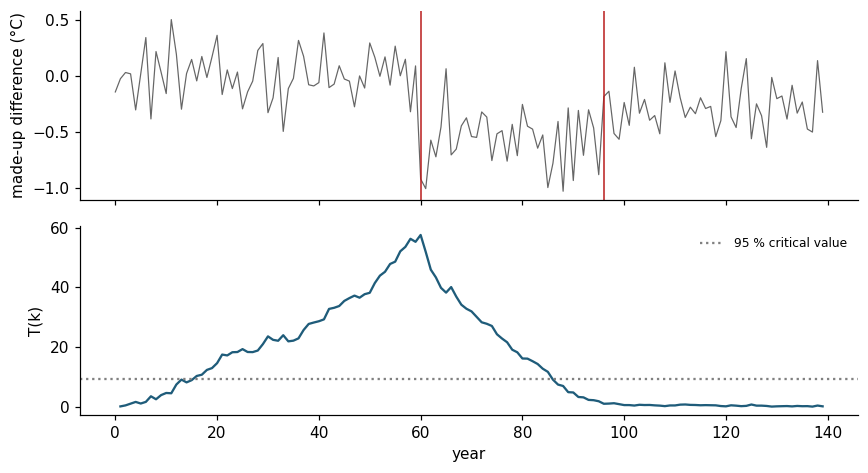

In [7]:
fig, axs = plt.subplots(2, 1, figsize=(8, 4.4), sharex=True)
axs[0].plot(fake, color="0.4", lw=0.8)
for b in find_breaks(fake):
    axs[0].axvline(b, color="#b91c1c", lw=1)
axs[0].set_ylabel("made-up difference (°C)")
z = (fake - fake.mean()) / fake.std(); cs = np.cumsum(z); k = np.arange(1, len(z))
axs[1].plot(k, k * (cs[:-1] / k) ** 2 + (len(z) - k) * ((cs[-1] - cs[:-1]) / (len(z) - k)) ** 2, color="#1f5c7a")
axs[1].axhline(critical(len(z)), color="0.5", ls=":", label="95 % critical value")
axs[1].set(xlabel="year", ylabel="T(k)")
axs[1].legend(frameon=False, fontsize=8)
plt.tight_layout()
plt.show()

Reading it: the top panel is the made-up series with the detected breaks (red lines). The bottom panel is $T(k)$
for the whole series: it peaks at the largest step, far above the dotted critical value.

## Applying it to real stations

For each of our 40 stations: find neighbours within 500 km in the raw monthly archive whose year-to-year changes
correlate with the station's at 0.6 or more over at least 30 years; keep the best 10; average their anomalies into
a reference; find breaks in station minus reference; and shift each earlier segment to the level of the latest.

In [8]:
stations = pd.read_fwf(open_member("qcu", ".inv"), colspecs=[(0, 11), (12, 20), (21, 30)], names=["id", "lat", "lon"]).set_index("id")


def anomalies(a, col="t"):
    base = a[a.year.between(1951, 1980)].groupby("id")[col].agg(["mean", "size"])
    base = base.loc[base["size"] >= 15, "mean"]
    a = a[a.id.isin(base.index)].copy()
    a["anom"] = a[col] - a.id.map(base)
    return a


pool = anomalies(raw).pivot(index="year", columns="id", values="anom").loc[1850:2024]
dpool = pool.diff()
plat, plon = np.deg2rad(stations.lat.reindex(pool.columns)).values, np.deg2rad(stations.lon.reindex(pool.columns)).values


def homogenise(y, lat, lon):
    lat, lon = np.deg2rad(lat), np.deg2rad(lon)
    dist = 6371 * np.arccos(np.clip(np.sin(lat) * np.sin(plat) + np.cos(lat) * np.cos(plat) * np.cos(plon - lon), -1, 1))
    near = pool.columns[(dist < 500) & (dist > 0)]
    dy = y.diff()
    cors = {nb: dy.corr(dpool[nb]) for nb in near if (dy.notna() & dpool[nb].notna()).sum() >= 30}
    nbs = [k for k, v in sorted(cors.items(), key=lambda kv: -kv[1]) if v >= 0.6][:10]
    if len(nbs) < 3:
        return y, [], None
    ref = pool[nbs].mean(axis=1)
    d = (y - ref).dropna()
    bk = find_breaks(d.values)
    adj = pd.Series(0.0, index=d.index)
    edges = [0] + bk + [len(d)]
    last = d.iloc[edges[-2]:].mean()
    for a, b in zip(edges[:-1], edges[1:]):
        adj.iloc[a:b] = last - d.iloc[a:b].mean()
    return y + adj.reindex(y.index).bfill().ffill(), [d.index[i] for i in bk], d


dan = anomalies(daily)
mine = {}
for sid, g in dan.groupby("id"):
    y = g.set_index("year").anom.loc[1850:2024]
    mine[sid], brk, d = homogenise(y, sample.loc[sid, "lat"], sample.loc[sid, "lon"])
mine = pd.DataFrame(mine)
print("homogenised", mine.shape[1], "stations")

homogenised 39 stations


## One station in detail

Let us look at one US station: the difference from its neighbours, the breaks found, and the corrected record.

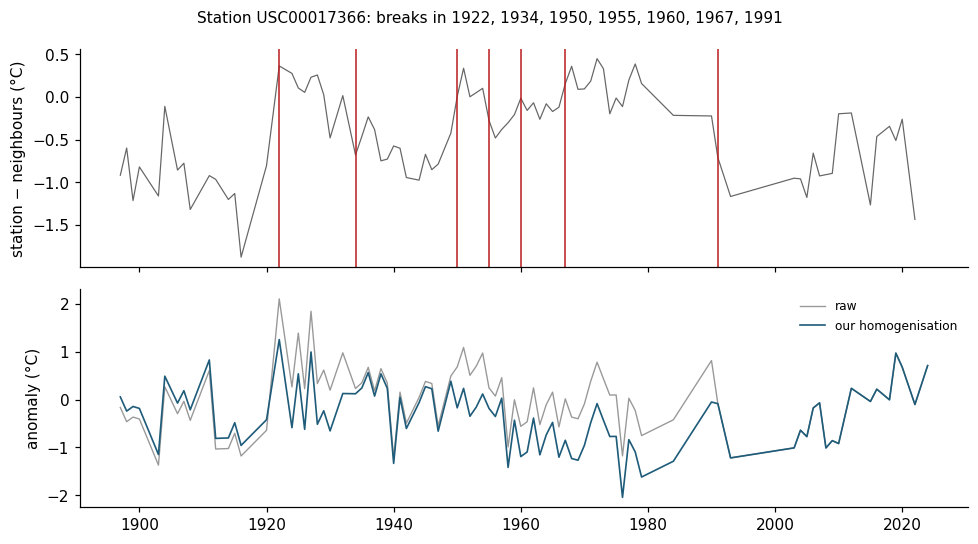

In [9]:
sid = next(s for s in mine.columns if s.startswith("US") and len(homogenise(dan[dan.id == s].set_index("year").anom.loc[1850:2024], sample.loc[s, "lat"], sample.loc[s, "lon"])[1]) >= 2)
y = dan[dan.id == sid].set_index("year").anom.loc[1850:2024]
yh, brk, d = homogenise(y, sample.loc[sid, "lat"], sample.loc[sid, "lon"])
fig, axs = plt.subplots(2, 1, figsize=(9, 5), sharex=True)
axs[0].plot(d.index, d, color="0.4", lw=0.8)
for b in brk:
    axs[0].axvline(b, color="#b91c1c", lw=1)
axs[0].set_ylabel("station − neighbours (°C)")
axs[1].plot(y.index, y, color="0.6", lw=0.9, label="raw")
axs[1].plot(yh.index, yh, color="#1f5c7a", lw=1.1, label="our homogenisation")
axs[1].set_ylabel("anomaly (°C)")
axs[1].legend(frameon=False, fontsize=8)
fig.suptitle(f"Station {sid}: breaks in {', '.join(map(str, brk))}", fontsize=10)
plt.tight_layout()
plt.show()

Reading it: the top panel is the station minus its neighbours; flat stretches separated by jumps are the
signature of station changes, and the red lines mark the jumps found. In the bottom panel the corrected record
(blue) is the raw one (grey) with each earlier stretch shifted by the size of its jump.

## What neighbour methods cannot see

In the full analysis this method, applied to all of the study's stations, changes the US averages very little,
while NOAA's corrections raise recent US warming considerably; outside the US our method and NOAA's agree. The
reason is a limit of every neighbour comparison: it detects changes at *one* station relative to others. When
almost every station in a region changes in the same years, the neighbours change too, and the difference series
stays flat. That happened in the US: most volunteer observers moved their reading time from afternoon to morning
over a few decades, and most switched to electronic sensors in the late 1980s. NOAA corrects these two with
**metadata** (records of when each station changed) and physical models of their effect, not only with
neighbours. An independent check is a different group's record: Berkeley Earth uses its own break detection and
statistical method.

In [10]:
be = pd.read_csv(get("berkeley_conus.txt", "https://berkeley-earth-temperature.s3.us-west-1.amazonaws.com/Regional/TAVG/"
                     "contiguous-united-states-TAVG-Trend.txt"), comment="%", sep=r"\s+", header=None, usecols=[0, 1, 2],
                 names=["year", "month", "anom"]).dropna()
be = be.groupby("year").filter(lambda g: len(g) == 12).groupby("year").anom.mean()
us_mean = lambda frame: frame[[c for c in frame.columns if c.startswith("US")]].mean(axis=1)
wide = lambda a: a.pivot(index="year", columns="id", values="anom").loc[1850:2024]
rows = {"raw (our 20 US stations)": us_mean(wide(dan)),
        "our homogenisation": us_mean(mine),
        "NOAA homogenisation": us_mean(wide(anomalies(noaa[noaa.id.isin(pick)]))),
        "Berkeley Earth, whole contiguous US": be}
tab = pd.DataFrame({k: window_trends(v) for k, v in rows.items()}).T.round(3)
print(tab.drop(columns="1857-1898"))       # before 1899 only one or two of our 20 US stations report

                                     1899-1940  1941-1982  1983-2024
raw (our 20 US stations)                 0.217     -0.193      0.157
our homogenisation                       0.151     -0.143      0.141
NOAA homogenisation                      0.227     -0.126      0.270
Berkeley Earth, whole contiguous US      0.165     -0.019      0.244


The first window is left out: before 1899 only one or two of these 20 stations report, so their average is not
meaningful. Reading the table: compare the last column (1983-2024) down the rows. Our homogenisation changes the
US stations little, while NOAA's raises recent warming. Berkeley Earth, made independently of NOAA,
agrees with NOAA that recent US warming is faster than the raw stations show, and faster than 1899-1940.

# The energy-balance model, 135 ways

The two-box model of the first notebook used one set of values: how much the climate eventually warms per unit of
forcing (its **sensitivity**), how that warming splits between a fast and a slow box, and the two timescales.
Here we vary all four over the ranges found in the literature and see whether the story of each period changes.

- equilibrium sensitivity 2.0 to 4.5 °C for doubled CO₂ (a doubling is 3.93 W/m² of forcing);
- fast share of the eventual warming 35 % to 55 %;
- fast timescale 2 to 8 years; slow timescale 100 to 500 years.

In [11]:
f = pd.read_csv(DATA / "forcing.csv").rename(columns={"Unnamed: 0": "year"})
f["year"] = f.year.astype(int)
f = f.set_index("year").loc[:2024]
g = pd.read_csv(DATA / "hadcrut5.csv").rename(columns={"Time": "year", "Anomaly (deg C)": "global"}).set_index("year")["global"]


def respond(F, tau, q):
    out = np.zeros(len(F))
    for t_, q_ in zip(tau, q):
        box, a = 0.0, np.exp(-1 / t_)
        for i, x in enumerate(F):
            box = box * a + q_ * x * (1 - a)
            out[i] += box
    return pd.Series(out, index=F.index)


causes = {"greenhouse gases and other": f.anthro - f.aerosol, "aerosols": f.aerosol, "solar": f.solar, "volcanic": f.volcanic}
results = []
for ecs in (2.0, 2.5, 3.0, 3.5, 4.5):
    for share in (0.35, 0.45, 0.55):
        for tf in (2, 4, 8):
            for ts in (100, 250, 500):
                q = (share * ecs / 3.93, (1 - share) * ecs / 3.93)
                parts = {k: respond(v, (tf, ts), q) for k, v in causes.items()}
                fit = sum(parts.values())
                fit += (g - fit).loc[1850:2024].mean()
                resid = (g - fit).loc[1850:2024]
                row = {"ecs": ecs, "share": share, "tau_fast": tf, "tau_slow": ts,
                       "R2": 1 - (resid ** 2).sum() / ((g.loc[1850:2024] - g.loc[1850:2024].mean()) ** 2).sum()}
                for a, b in [(1910, 1945), (1946, 1975), (1976, 2024)]:
                    for k, v in parts.items():
                        row[f"{k} {a}-{b}"] = trend(v.loc[a:b].index, v.loc[a:b].values)
                    row[f"unexplained {a}-{b}"] = trend(resid.loc[a:b].index, resid.loc[a:b].values)
                results.append(row)
ebm = pd.DataFrame(results)
print(len(ebm), "versions; R² from", round(ebm.R2.min(), 2), "to", round(ebm.R2.max(), 2))
print(ebm.sort_values("R2").tail(3)[["ecs", "share", "tau_fast", "tau_slow", "R2"]])
good = ebm[ebm.R2 >= ebm.R2.quantile(0.75)]
print("\nrange over the best-fitting quarter of versions (°C/decade):")
print(good.filter(like="-").agg(["min", "max"]).T.round(3))

135 versions; R² from 0.35 to 0.91
    ecs  share  tau_fast  tau_slow        R2
78  3.0   0.55         8       100  0.907551
84  3.5   0.35         4       100  0.908231
87  3.5   0.35         8       100  0.910312

range over the best-fitting quarter of versions (°C/decade):
                                        min    max
greenhouse gases and other 1910-1945  0.050  0.075
aerosols 1910-1945                   -0.037 -0.021
solar 1910-1945                       0.004  0.006
volcanic 1910-1945                    0.008  0.018
unexplained 1910-1945                 0.097  0.114
greenhouse gases and other 1946-1975  0.092  0.133
aerosols 1946-1975                   -0.122 -0.084
solar 1946-1975                      -0.000  0.004
volcanic 1946-1975                   -0.017 -0.002
unexplained 1946-1975                -0.017  0.007
greenhouse gases and other 1976-2024  0.191  0.286
aerosols 1976-2024                   -0.034  0.013
solar 1976-2024                      -0.005 -0.002
volcanic 

Reading it: the best-fitting versions explain about 91 % of the variance, close to the single version used
before. Over the best-fitting quarter, greenhouse gases supply most of the 1976-2024 warming, aerosols cancel most of
the mid-century greenhouse warming, and the unexplained part of 1910-1945 stays at about 0.1 °C per decade. Even
over all 135 versions, including poorly fitting ones, the unexplained early warming stays between about 0.07 and
0.14. The conclusions do not hang on the chosen timescales.

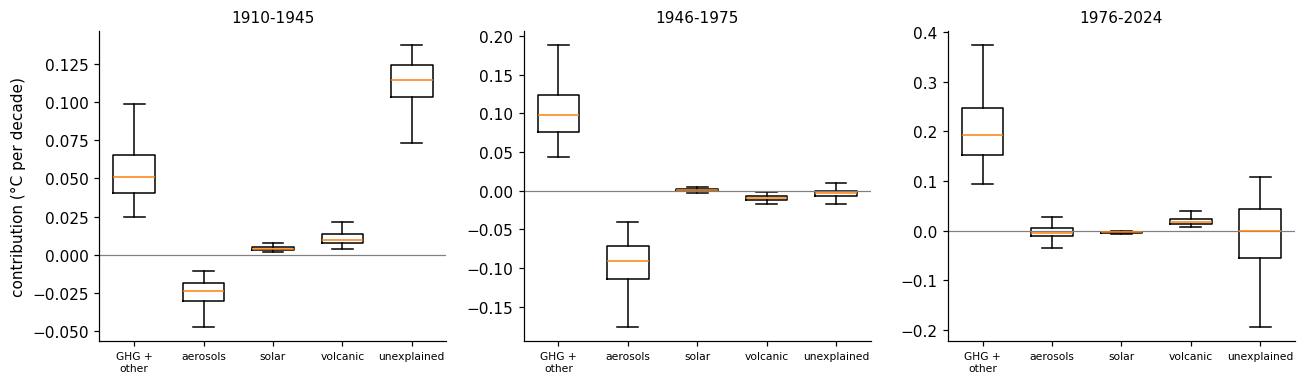

In [12]:
fig, axs = plt.subplots(1, 3, figsize=(12, 3.6))
for ax, per_ in zip(axs, ["1910-1945", "1946-1975", "1976-2024"]):
    cols = [c for c in ebm.columns if c.endswith(per_)]
    ax.boxplot([ebm[c] for c in cols], widths=0.6, showfliers=False)
    ax.set_xticks(range(1, len(cols) + 1))
    ax.set_xticklabels([c.replace(" " + per_, "").replace("greenhouse gases and other", "GHG +\nother") for c in cols], fontsize=7)
    ax.axhline(0, color="0.5", lw=0.8)
    ax.set_title(per_, fontsize=10)
axs[0].set_ylabel("contribution (°C per decade)")
plt.tight_layout()
plt.show()

Reading it: a **box plot** summarises many values: the box spans the middle half, the line inside is the median,
and the whiskers reach the range. One panel per period, one box per cause, across all 135 versions.

# Many runs of one model

A climate model run with slightly different starting weather produces a different sequence of El Niños and ocean
swings, while the forcing is identical. Comparing several runs of one model therefore measures **chance** in that
model's climate. We read 10 runs each of two models from the cloud. As explained in notebook 2, a chunk that
fails to download is silently filled with missing values, so we insist that every grid cell is present and retry
otherwise.

In [13]:
import xarray as xr

cat = pd.read_csv(get("pangeo-cmip6.csv", "https://storage.googleapis.com/cmip6/pangeo-cmip6.csv"))
q_ = cat[cat.experiment_id.isin(["historical", "ssp245"]) & (cat.table_id == "Amon") & (cat.variable_id == "tas")]


def global_mean(store, tries=4):
    for k in range(tries):
        ds = xr.open_zarr(store.replace("gs://", "https://storage.googleapis.com/"), consolidated=True)
        w = np.cos(np.deg2rad(ds.lat))
        s = ds.tas.weighted(w).mean(("lat", "lon"), skipna=False).groupby("time.year").mean(skipna=False).to_series()
        if s.notna().all():
            return s
        time.sleep(5)
    raise RuntimeError("incomplete download")


runs = {}
for model in ("MIROC6", "CanESM5"):
    have = sorted(set(q_[(q_.source_id == model) & (q_.experiment_id == "historical")].member_id)
                  & set(q_[(q_.source_id == model) & (q_.experiment_id == "ssp245")].member_id),
                  key=lambda m: int(m[1:].split("i")[0]))[:10]
    for mem in have:
        cache = DATA / f"cmip6_{model}_{mem}.csv"
        if not cache.exists():
            sel = q_[(q_.source_id == model) & (q_.member_id == mem)]
            parts = [global_mean(sel[sel.experiment_id == e].sort_values("version").zstore.iloc[-1]) for e in ("historical", "ssp245")]
            pd.concat([parts[0], parts[1][parts[1].index > parts[0].index.max()]]).loc[1850:2024].to_csv(cache)
        s = pd.read_csv(cache, index_col=0).iloc[:, 0]
        runs[(model, mem)] = s - s.loc[1850:1900].mean()
runs = pd.DataFrame(runs)
tr = pd.DataFrame({k: window_trends(runs[k]) | {"1910-1945": trend(np.arange(1910, 1946), runs[k].loc[1910:1945].values)} for k in runs.columns}).T
print(tr.groupby(level=0).agg(["min", "max"]).round(3).T)
print("\nruns in which 1983-2024 is the fastest of the four windows:", int((tr[[f"{a}-{b}" for a, b in WINDOWS]].idxmax(axis=1) == "1983-2024").sum()), "of", len(tr))

               CanESM5  MIROC6
1857-1898 min   -0.057  -0.040
          max    0.036   0.024
1899-1940 min    0.052   0.043
          max    0.123   0.085
1941-1982 min   -0.012  -0.040
          max    0.046   0.031
1983-2024 min    0.360   0.168
          max    0.486   0.220
1910-1945 min    0.047   0.048
          max    0.134   0.107

runs in which 1983-2024 is the fastest of the four windows: 20 of 20


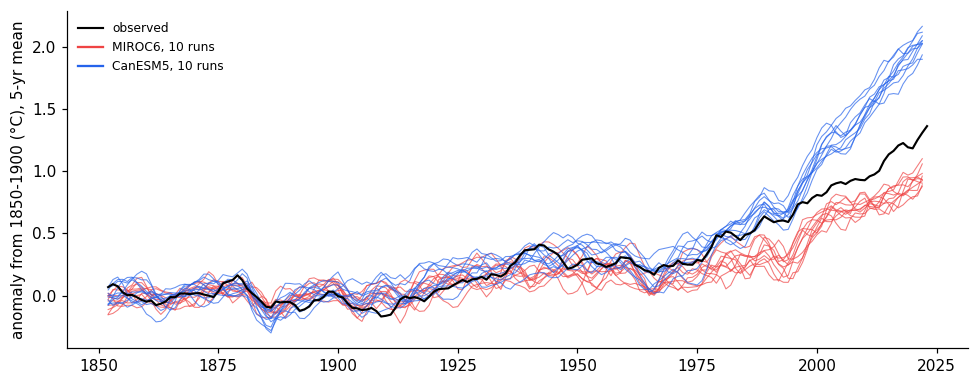

In [14]:
fig, ax = plt.subplots(figsize=(9, 3.6))
for (model, mem), colr in zip(runs.columns, ["#ef4444"] * 10 + ["#2563eb"] * 10):
    ax.plot(runs.index, runs[(model, mem)].rolling(5, center=True).mean(), color=colr, lw=0.7, alpha=0.7)
ax.plot(g.index, (g - g.loc[1850:1900].mean()).rolling(5, center=True).mean(), color="k", lw=1.4, label="observed")
ax.plot([], [], color="#ef4444", label="MIROC6, 10 runs"); ax.plot([], [], color="#2563eb", label="CanESM5, 10 runs")
ax.set(ylabel="anomaly from 1850-1900 (°C), 5-yr mean")
ax.legend(frameon=False, fontsize=8)
plt.tight_layout()
plt.show()

Reading it: runs of one model (one colour) share the forcing and the model's physics; they differ only by chance,
and the spread between them is the size of chance. The two models differ more from each other than their runs do
(CanESM5 is known to be one of the most sensitive models). In every run the last window warms fastest; the early
window varies between runs by several hundredths of a degree per decade, which is how much an unlucky or lucky
sequence of ocean swings can add.

# Every window, not just four

The study chose four 42-year windows. A **heat map** shows the trend for every start year (horizontal) and every
window length from 20 to 60 years (vertical); colour is the trend.

for every window length from 20 to 60 years, the fastest window ends in: [2019, 2020, 2024]


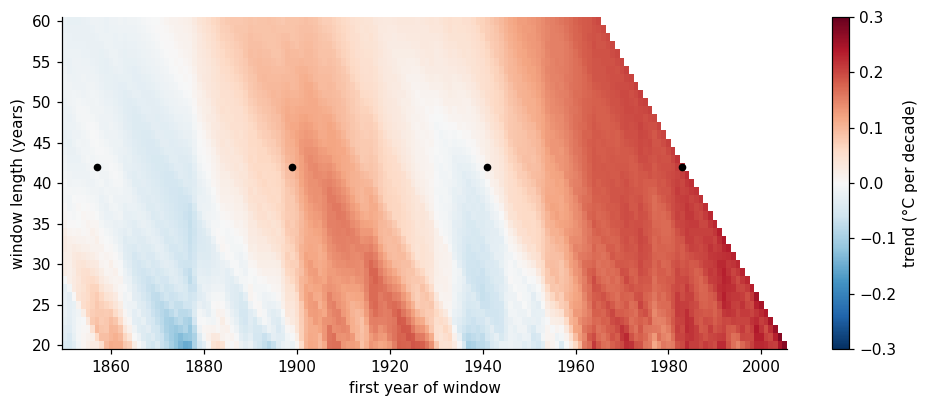

In [15]:
L, S0 = np.arange(20, 61), np.arange(1850, 2006)
M = np.full((len(L), len(S0)), np.nan)
for i, n in enumerate(L):
    for j, a in enumerate(S0):
        if a + n - 1 <= 2024:
            M[i, j] = trend(np.arange(a, a + n), g.loc[a:a + n - 1].values)
fastest_end = [int(S0[np.nanargmax(M[i])] + n - 1) for i, n in enumerate(L)]
print("for every window length from 20 to 60 years, the fastest window ends in:", sorted(set(fastest_end)))

fig, ax = plt.subplots(figsize=(9, 3.8))
im = ax.pcolormesh(S0, L, M, cmap="RdBu_r", vmin=-0.3, vmax=0.3, shading="nearest")
for a, b in WINDOWS:
    ax.plot(a, 42, "ko", ms=4)
ax.set(xlabel="first year of window", ylabel="window length (years)")
fig.colorbar(im, ax=ax, label="trend (°C per decade)")
plt.tight_layout()
plt.show()

Reading it: red is warming, blue cooling; the black dots are the study's four windows. The deepest red is always
at the right-hand edge, in windows that end in the last few years, whatever the length. The early-twentieth-century
band is visible as a pale red stripe starting around 1900-1915, but it never reaches the colour of the recent band.

# What this notebook adds

| Shortcut removed | What changed | Does recent warming stay the fastest? |
|---|---|---|
| Daily instead of monthly data | Per-station trends are identical; the daily archive loses non-US stations after 2010 | Yes, once stations are weighted by area |
| Own homogenisation | Finds about four breaks per station; fixes isolated changes, not network-wide ones | Yes outside the US; for the US, NOAA and Berkeley Earth agree it does |
| 135 energy-balance versions | Contributions vary in size, not in sign or ordering | Yes |
| Ten runs per model | Chance moves early trends by a few hundredths | Yes, in every run |
| Every window | Any start year, any length from 20 to 60 years | Yes |

# Recording what the run used

In [16]:
import json
print(json.dumps({"numpy": np.__version__, "pandas": pd.__version__, "xarray": xr.__version__,
                  "daily_stations": len(pick), "minutes": round((time.time() - t_start) / 60, 1)}, indent=1))

{
 "numpy": "2.0.1",
 "pandas": "2.2.3",
 "xarray": "2025.4.0",
 "daily_stations": 40,
 "minutes": 0.8
}
